# 02 - EDA, Taksonomi Aspek, dan Gold Set

## Setup

In [9]:
!pip install -q matplotlib

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FOLDER_PROJECT = Path('/content/drive/MyDrive/ulasan-ewallet')
FOLDER_PROCESSED = FOLDER_PROJECT / 'data' / 'processed'
SEED = 42

df = pd.read_parquet(FOLDER_PROCESSED / 'ulasan_bersih.parquet')
df['negatif'] = df['rating'] <= 2
df['positif'] = df['rating'] >= 4
print(f'{len(df):,} ulasan bersih:', df.groupby('aplikasi').size().to_dict())

398,742 ulasan bersih: {'dana': 239965, 'gopay': 135899, 'ovo': 22878}


In [12]:
from matplotlib.transforms import offset_copy

# Palet kategorikal tervalidasi (3 slot pertama aman untuk buta warna); warna mengikuti aplikasi, tidak pernah berubah
URUTAN_APLIKASI = ['dana', 'gopay', 'ovo']
NAMA = {'dana': 'DANA', 'gopay': 'GoPay', 'ovo': 'OVO'}
WARNA = {'dana': '#2a78d6', 'gopay': '#eb6834', 'ovo': '#1baf7a'}
PERMUKAAN = '#fcfcfb'
TINTA, TINTA_2, TINTA_REDUP = '#0b0b0b', '#52514e', '#898781'

plt.rcParams.update({
    'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'figure.facecolor': PERMUKAAN, 'axes.facecolor': PERMUKAAN,
    'font.family': 'sans-serif', 'font.size': 10,
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.titlecolor': TINTA,
    'axes.labelcolor': TINTA_2,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'xtick.color': '#c3c2b7', 'ytick.color': '#c3c2b7',
    'xtick.labelcolor': TINTA_REDUP, 'ytick.labelcolor': TINTA_REDUP,
    'lines.linewidth': 2, 'lines.markersize': 6,
    'legend.frameon': False, 'legend.labelcolor': TINTA_2,
})


def grafik_garis(data, x, y, judul, label_y, label_x=None, putar_label=False):
    """Satu garis per aplikasi, legenda + label langsung di ujung garis (digeser bila bertumpuk)."""
    fig, ax = plt.subplots()
    ujung = []
    for nama in URUTAN_APLIKASI:
        d = data[data['aplikasi'] == nama]
        ax.plot(d[x].astype(str), d[y], marker='o', color=WARNA[nama], label=NAMA[nama],
                markeredgecolor=PERMUKAAN, markeredgewidth=1.5)
        ujung.append([d[y].iloc[-1], nama, len(d) - 1])
    y_min, y_max = ax.get_ylim()
    jarak = 0.05 * (y_max - y_min)
    ujung.sort()
    for k in range(1, len(ujung)):
        ujung[k][0] = max(ujung[k][0], ujung[k - 1][0] + jarak)
    geser = offset_copy(ax.transData, fig=fig, x=8, y=0, units='points')
    for y_label, nama, x_akhir in ujung:
        ax.text(x_akhir, y_label, NAMA[nama], transform=geser, va='center', color=TINTA_2)
    ax.set_title(judul, pad=28)
    ax.set_ylabel(label_y)
    if label_x:
        ax.set_xlabel(label_x)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
    if putar_label:
        ax.tick_params(axis='x', rotation=45)
    plt.show()


# Fase 3 - EDA
## 3.1 Tren bulanan: volume dan persen ulasan negatif

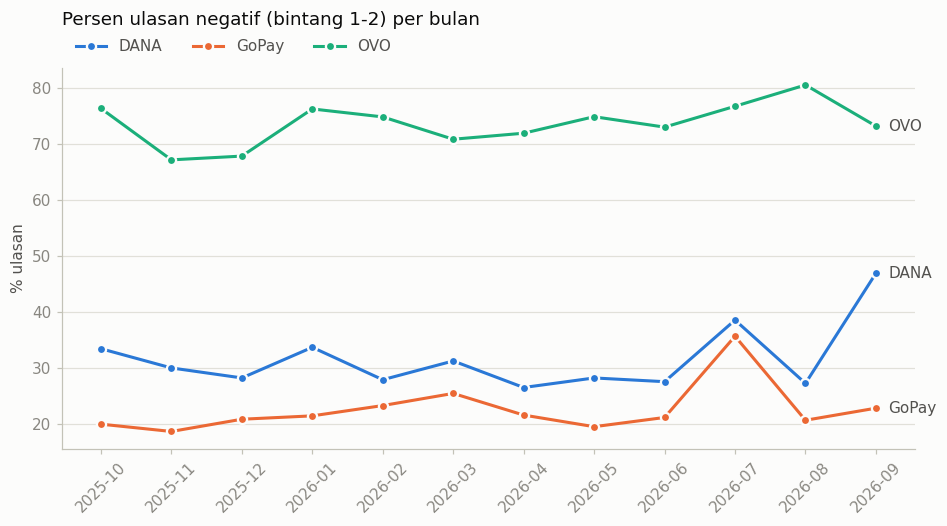

jumlah                  persen_negatif             rating_rata2  \
aplikasi     dana    gopay     ovo           dana gopay   ovo         dana   
bulan                                                                        
2025-10   18047.0  11945.0  2356.0           33.5  20.0  76.4          3.5   
2025-11   17452.0  11090.0  2020.0           30.1  18.7  67.2          3.7   
2025-12   20392.0  11194.0  2056.0           28.3  20.9  67.9          3.7   
2026-01   24213.0  12336.0  2473.0           33.7  21.5  76.3          3.5   
2026-02   19787.0   9403.0  1725.0           28.0  23.3  74.8          3.7   
2026-03   21581.0  11251.0  1527.0           31.3  25.5  70.9          3.6   
2026-04   15679.0   9133.0  1874.0           26.6  21.6  71.9          3.8   
2026-05   16739.0  10091.0  1680.0           28.3  19.6  74.9          3.7   
2026-06   16266.0  11297.0  1627.0           27.6  21.2  73.0          3.8   
2026-07   24234.0  14854.0  1883.0           38.6  35.7  76.7          3.4   
2026-08   17824.0  11482.0  2004.0           27.3  20.7  80.5          3.8   
2026-09   27751.0  11823.0  1653.0           46.9  22.9  73.2          3.0   

                     
aplikasi gopay  ovo  
bulan                
2025-10    4.1  1.9  
2025-11    4.1  2.2  
2025-12    4.0  2.2  
2026-01    4.0  1.9  
2026-02    4.0  2.0  
2026-03    3.9  2.1  
2026-04    4.0  2.1  
2026-05    4.1  2.0  
2026-06    4.0  2.0  
2026-07    3.5  1.9  
2026-08    4.1  1.7  
2026-09    4.0  2.0

In [13]:
bulanan = df.groupby(['aplikasi', 'bulan']).agg(
    jumlah=('id_ulasan', 'size'),
    persen_negatif=('negatif', 'mean'),
    rating_rata2=('rating', 'mean'),
).reset_index()
bulanan['persen_negatif'] *= 100

grafik_garis(bulanan, 'bulan', 'persen_negatif', 'Persen ulasan negatif (bintang 1-2) per bulan', '% ulasan',
             putar_label=True)
display(bulanan.pivot(index='bulan', columns='aplikasi', values=['jumlah', 'persen_negatif', 'rating_rata2']).round(1))

## 3.2 Volume harian dan hari lonjakan

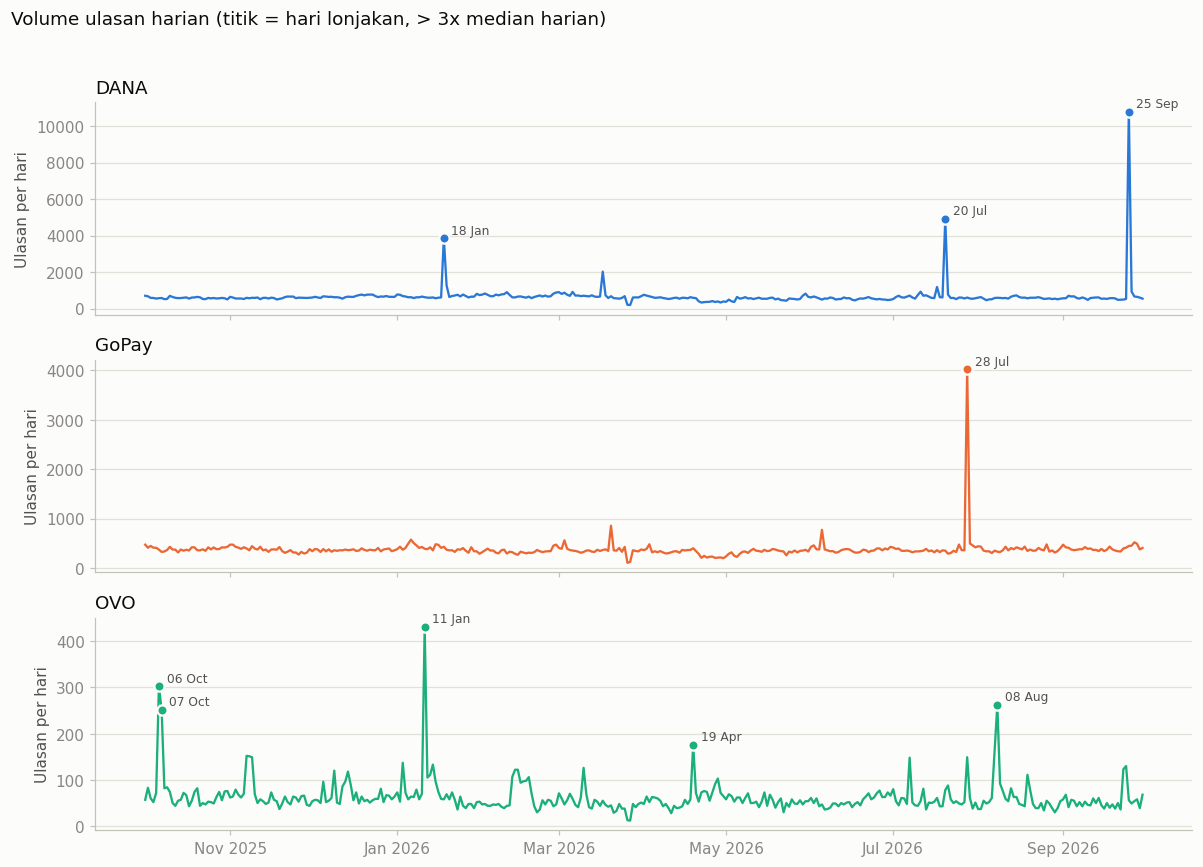

Hari lonjakan:


,aplikasi,hari,jumlah,persen_negatif,lonjakan
109,dana,2026-01-18,3852,65.0,True
292,dana,2026-07-20,4899,73.3,True
359,dana,2026-09-25,10793,73.7,True
665,gopay,2026-07-28,4021,71.2,True
735,ovo,2025-10-06,302,91.1,True
736,ovo,2025-10-07,252,83.7,True
832,ovo,2026-01-11,430,85.8,True
930,ovo,2026-04-19,176,86.4,True
1041,ovo,2026-08-08,262,90.5,True


In [14]:
harian = df.groupby(['aplikasi', df['tanggal'].dt.normalize().rename('hari')]).agg(
    jumlah=('id_ulasan', 'size'),
    persen_negatif=('negatif', 'mean'),
    lonjakan=('hari_lonjakan', 'max'),
).reset_index()
harian['persen_negatif'] *= 100

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(11, 8))
for ax, nama in zip(axes, URUTAN_APLIKASI):
    d = harian[harian['aplikasi'] == nama]
    ax.plot(d['hari'], d['jumlah'], color=WARNA[nama], linewidth=1.5)
    puncak = d[d['lonjakan']]
    ax.scatter(puncak['hari'], puncak['jumlah'], s=45, color=WARNA[nama], edgecolor=PERMUKAAN, linewidth=1.5, zorder=3)
    for _, r in puncak.iterrows():
        ax.annotate(f"{r['hari']:%d %b}", (r['hari'], r['jumlah']), xytext=(5, 3), textcoords='offset points',
                    fontsize=8, color=TINTA_2)
    ax.set_title(NAMA[nama])
    ax.set_ylabel('Ulasan per hari')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.suptitle('Volume ulasan harian (titik = hari lonjakan, > 3x median harian)', x=0.01, ha='left', color=TINTA)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print('Hari lonjakan:')
display(harian[harian['lonjakan']].round(1))

## 3.3 Panjang ulasan vs rating

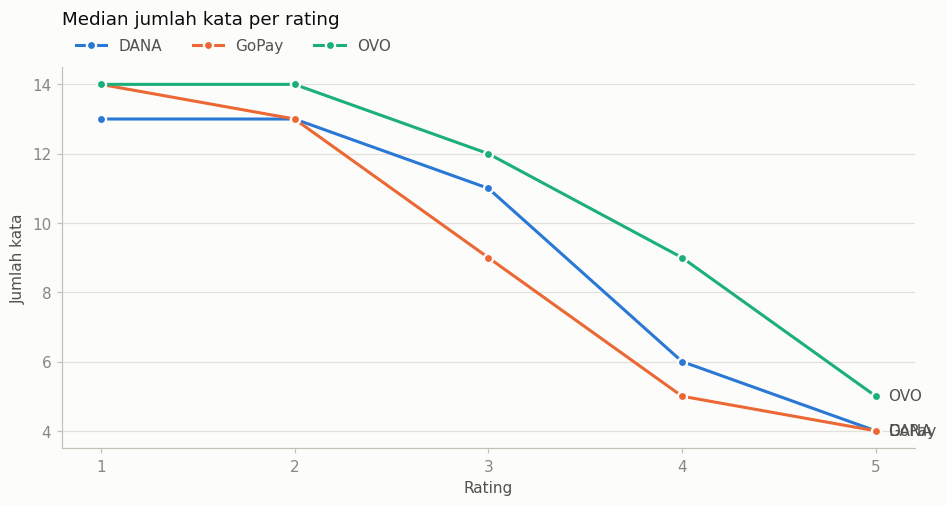

rating,1,2,3,4,5
aplikasi,,,,,
dana,13.0,13.0,11.0,6.0,4.0
gopay,14.0,13.0,9.0,5.0,4.0
ovo,14.0,14.0,12.0,9.0,5.0


DANA: korelasi Spearman jumlah kata vs rating = -0.51
GoPay: korelasi Spearman jumlah kata vs rating = -0.48
OVO: korelasi Spearman jumlah kata vs rating = -0.29


In [15]:
panjang = df.groupby(['aplikasi', 'rating'])['jumlah_kata'].median().reset_index()
grafik_garis(panjang, 'rating', 'jumlah_kata', 'Median jumlah kata per rating', 'Jumlah kata', label_x='Rating')
display(panjang.pivot(index='aplikasi', columns='rating', values='jumlah_kata'))

for nama in URUTAN_APLIKASI:
    d = df[df['aplikasi'] == nama]
    print(f"{NAMA[nama]}: korelasi Spearman jumlah kata vs rating = {d['jumlah_kata'].corr(d['rating'], method='spearman'):.2f}")

## 3.4 Kata dan bigram khas: weighted log-odds

In [16]:
def hitung_ngram(daftar_teks):
    hitung = Counter()
    for teks in daftar_teks:
        kata = teks.split()
        hitung.update(kata)
        hitung.update(' '.join(p) for p in zip(kata, kata[1:]))
    return hitung


def log_odds(hitung_a, hitung_b, min_frek=30):
    """Weighted log-odds, prior Dirichlet dari gabungan kedua kelompok (Monroe dkk., 2008). z > 0 = khas kelompok a."""
    latar = hitung_a + hitung_b
    n_a, n_b, alpha0 = sum(hitung_a.values()), sum(hitung_b.values()), sum(latar.values())
    hasil = []
    for w, alpha in latar.items():
        if alpha < min_frek:
            continue
        ya, yb = hitung_a.get(w, 0), hitung_b.get(w, 0)
        delta = (np.log((ya + alpha) / (n_a + alpha0 - ya - alpha))
                 - np.log((yb + alpha) / (n_b + alpha0 - yb - alpha)))
        hasil.append((w, ya, yb, delta / np.sqrt(1 / (ya + alpha) + 1 / (yb + alpha))))
    return pd.DataFrame(hasil, columns=['ngram', 'frek_a', 'frek_b', 'z']).sort_values('z', ascending=False)


def cetak_teratas(hasil, label_a, label_b, n=30):
    print(f'  Khas {label_a}: ' + ', '.join(f'{w} ({z:.0f})' for w, z in hasil.head(n)[['ngram', 'z']].values))
    print(f'  Khas {label_b}: ' + ', '.join(f'{w} ({-z:.0f})' for w, z in hasil.tail(n)[::-1][['ngram', 'z']].values))


hitung_negatif, hitung_positif = {}, {}
print('A. Negatif vs positif per aplikasi (angka = skor z)')
for nama in URUTAN_APLIKASI:
    d = df[df['aplikasi'] == nama]
    hitung_negatif[nama] = hitung_ngram(d.loc[d['negatif'], 'teks_penuh'])
    hitung_positif[nama] = hitung_ngram(d.loc[d['positif'], 'teks_penuh'])
    print(f'\n{NAMA[nama]}')
    cetak_teratas(log_odds(hitung_negatif[nama], hitung_positif[nama]), 'negatif', 'positif')

print('\n\nB. Keluhan khas tiap aplikasi (ulasan negatif: aplikasi ini vs dua lainnya)')
for nama in URUTAN_APLIKASI:
    lainnya = sum((hitung_negatif[n] for n in URUTAN_APLIKASI if n != nama), Counter())
    hasil = log_odds(hitung_negatif[nama], lainnya, min_frek=20)
    print(f'\n{NAMA[nama]}: ' + ', '.join(f'{w} ({z:.0f})' for w, z in hasil.head(30)[['ngram', 'z']].values))

A. Negatif vs positif per aplikasi (angka = skor z)

DANA
  Khas negatif: tidak (50), saldo (37), hilang (32), malah (29), tiba (29), jelas (29), tidak jelas (28), tidak bisa (27), mau (25), padahal (23), terus (21), error (21), masuk (21), kecewa (21), uang (21), jelek (20), sama (20), cs (20), buruk (20), tiba tiba (18), aplikasi tidak (18), tidak masuk (18), parah (17), gangguan (17), terpotong (17), aneh (16), makin (16), gagal (16), nomor (15), masa (15)
  Khas positif: sangat (141), bagus (99), membantu (98), sangat membantu (92), mudah (67), sangat bagus (67), mantap (63), baik (56), cepat (55), sangat baik (47), puas (45), terima kasih (44), oke (43), terima (42), sangat puas (39), cicil (37), kasih (37), dana cicil (37), semoga (34), bermanfaat (33), bagus banget (31), aplikasi sangat (31), sangat mudah (31), sekali (31), bagus sekali (31), dana (29), keren (29), memudahkan (28), praktis (28), good (28)

GoPay
  Khas negatif: tidak (58), masuk (37), tidak bisa (32), saldo (31)

## 3.5 Rating per versi aplikasi

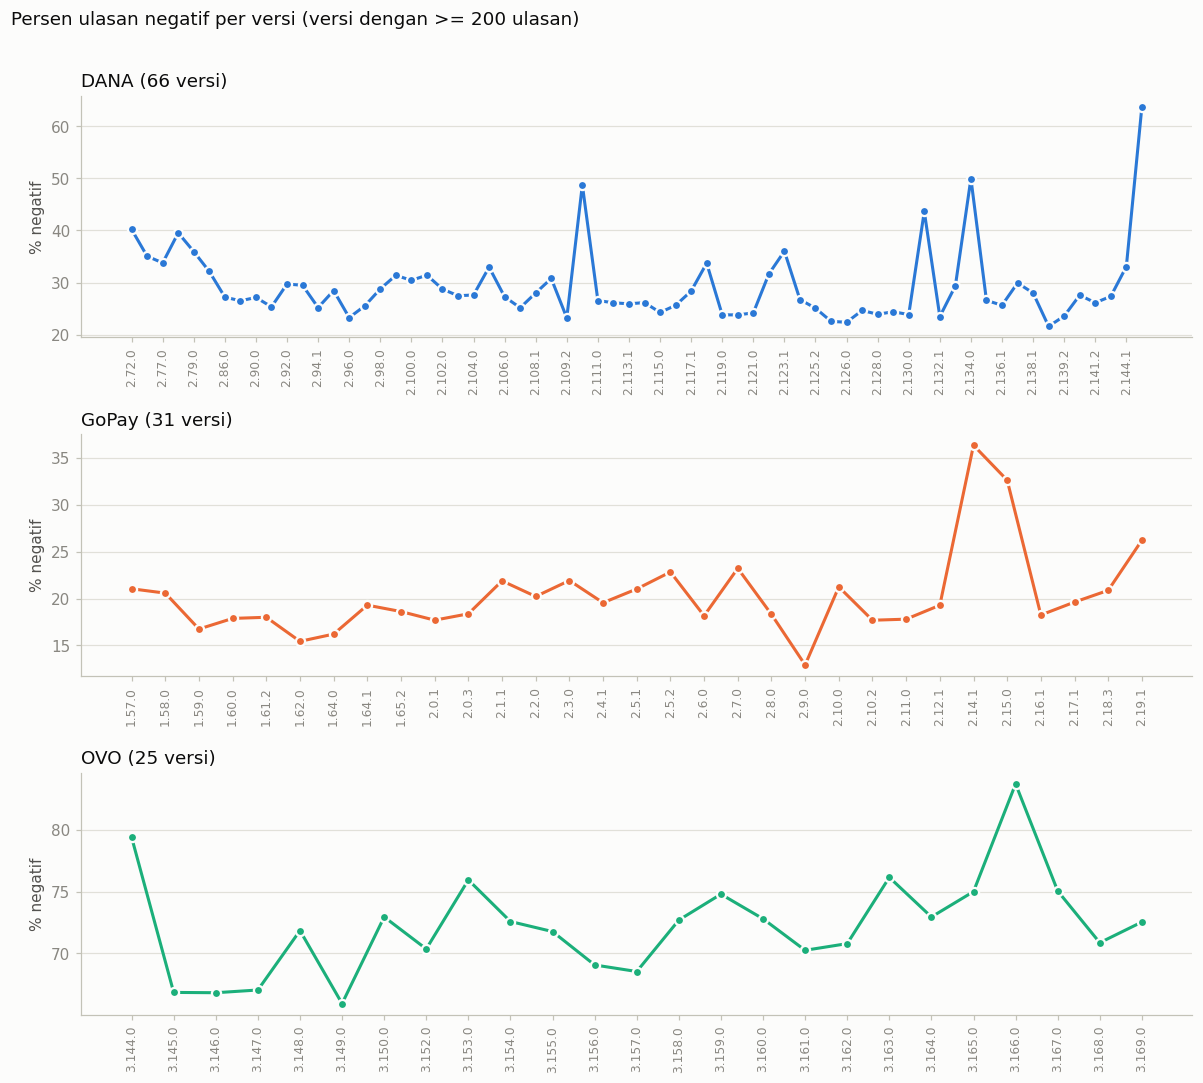

Jumlah versi yang ditampilkan: {'dana': 66, 'gopay': 31, 'ovo': 25}

DANA: 5 versi dengan persen negatif tertinggi dan terendah


,versi,jumlah,persen_negatif,rating_rata2,pertama_muncul
115,2.145.0,9438,63.7,2.3,2026-09-19 16:38:09
97,2.134.0,6728,49.9,2.9,2026-07-11 00:09:19
60,2.110.0,5027,48.7,2.9,2026-01-10 23:14:40
93,2.131.1,1737,43.6,3.2,2026-06-23 18:49:40
208,2.72.0,301,40.2,3.3,2025-10-02 00:30:28
105,2.139.0,804,21.6,4.0,2026-08-14 10:02:40
85,2.126.0,2414,22.4,4.0,2026-05-16 10:49:57
84,2.125.3,2394,22.6,4.0,2026-05-13 20:33:43
57,2.109.2,11524,23.3,4.0,2025-12-23 16:51:51
238,2.96.0,519,23.3,3.9,2025-10-01 02:18:52



GoPay: 5 versi dengan persen negatif tertinggi dan terendah


,versi,jumlah,persen_negatif,rating_rata2,pertama_muncul
317,2.14.1,4474,36.3,3.4,2026-07-11 17:31:26
318,2.15.0,5852,32.6,3.6,2026-07-22 16:40:42
324,2.19.1,679,26.2,3.9,2026-09-18 08:30:28
333,2.7.0,2773,23.2,4.0,2026-04-15 19:58:15
331,2.5.2,5396,22.8,4.0,2026-03-18 01:11:54
335,2.9.0,565,12.9,4.4,2026-05-15 01:22:57
298,1.62.0,3485,15.4,4.3,2025-11-01 13:57:12
299,1.64.0,1974,16.2,4.2,2025-11-14 05:20:34
293,1.59.0,3409,16.7,4.2,2025-10-01 00:00:55
312,2.10.2,2482,17.7,4.2,2026-06-04 19:41:11



OVO: 5 versi dengan persen negatif tertinggi dan terendah


,versi,jumlah,persen_negatif,rating_rata2,pertama_muncul
408,3.166.0,798,83.7,1.6,2026-07-28 16:33:07
387,3.144.0,1199,79.4,1.8,2025-10-01 00:33:48
405,3.163.0,608,76.2,1.9,2026-06-16 10:31:24
395,3.153.0,952,75.9,1.9,2026-01-28 23:55:53
409,3.167.0,505,75.0,1.9,2026-08-12 15:53:15
392,3.149.0,646,65.9,2.3,2025-12-05 16:09:19
389,3.146.0,645,66.8,2.2,2025-10-24 14:29:38
388,3.145.0,371,66.8,2.3,2025-10-15 11:27:11
390,3.147.0,622,67.0,2.2,2025-11-04 19:44:52
399,3.157.0,410,68.5,2.2,2026-03-28 18:41:37


In [17]:
MIN_ULASAN_VERSI = 200


def kunci_versi(v):
    return tuple(int(x) for x in re.findall(r'\d+', v))


versi = (
    df[df['versi'].fillna('') != '']
    .groupby(['aplikasi', 'versi']).agg(
        jumlah=('id_ulasan', 'size'),
        rating_rata2=('rating', 'mean'),
        persen_negatif=('negatif', 'mean'),
        pertama_muncul=('tanggal', 'min'),
    ).reset_index()
)
versi = versi[versi['jumlah'] >= MIN_ULASAN_VERSI].copy()
versi['persen_negatif'] *= 100
versi['kunci'] = versi['versi'].map(kunci_versi)
versi = versi.sort_values(['aplikasi', 'kunci'])

fig, axes = plt.subplots(3, 1, figsize=(11, 10))
for ax, nama in zip(axes, URUTAN_APLIKASI):
    d = versi[versi['aplikasi'] == nama]
    posisi = list(range(len(d)))
    ax.plot(posisi, d['persen_negatif'], marker='o', color=WARNA[nama],
            markeredgecolor=PERMUKAAN, markeredgewidth=1.5)
    langkah = max(1, len(d) // 25)
    ax.set_xticks(posisi[::langkah])
    ax.set_xticklabels(d['versi'].iloc[::langkah], rotation=90, fontsize=8)
    ax.set_title(f'{NAMA[nama]} ({len(d)} versi)')
    ax.set_ylabel('% negatif')
fig.suptitle(f'Persen ulasan negatif per versi (versi dengan >= {MIN_ULASAN_VERSI} ulasan)',
             x=0.01, ha='left', color=TINTA)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

print('Jumlah versi yang ditampilkan:', versi.groupby('aplikasi').size().to_dict())
kolom = ['versi', 'jumlah', 'persen_negatif', 'rating_rata2', 'pertama_muncul']
for nama in URUTAN_APLIKASI:
    d = versi[versi['aplikasi'] == nama]
    print(f'\n{NAMA[nama]}: 5 versi dengan persen negatif tertinggi dan terendah')
    display(pd.concat([d.nlargest(5, 'persen_negatif'), d.nsmallest(5, 'persen_negatif')])[kolom].round(1))

## 3.6 Balasan developer dan jumlah suka

In [18]:
df['dibalas'] = df['balasan'].notna()
print('Persen ulasan yang dibalas developer, per rating (%):')
display(df.pivot_table(index='aplikasi', columns='rating', values='dibalas', aggfunc='mean').mul(100).round(1))

df['jam_sampai_balasan'] = (df['tanggal_balasan'] - df['tanggal']).dt.total_seconds() / 3600
print('Jam dari ulasan sampai balasan (ulasan yang dibalas):')
display(df[df['dibalas']].groupby('aplikasi')['jam_sampai_balasan'].describe(percentiles=[0.5, 0.9]).round(1))

print('Rata-rata jumlah suka (thumbs up) per rating:')
display(df.pivot_table(index='aplikasi', columns='rating', values='jumlah_suka', aggfunc='mean').round(2))

Persen ulasan yang dibalas developer, per rating (%):


rating,1,2,3,4,5
aplikasi,,,,,
dana,75.5,78.5,77.7,25.0,11.2
gopay,85.0,78.0,56.2,1.4,0.5
ovo,1.7,1.7,1.9,3.3,1.3


Jam dari ulasan sampai balasan (ulasan yang dibalas):


,count,mean,std,min,50%,90%,max
aplikasi,,,,,,,
dana,87768.0,-661.7,4376.7,-68112.3,1.4,8.7,112.5
gopay,29710.0,-103.2,1249.9,-30124.5,1.1,144.8,621.8
ovo,393.0,-30430.4,14118.5,-67675.1,-26386.7,-15179.9,-9619.3


Rata-rata jumlah suka (thumbs up) per rating:


rating,1,2,3,4,5
aplikasi,,,,,
dana,0.66,0.69,0.49,0.51,0.63
gopay,1.59,0.57,0.49,0.33,0.32
ovo,1.12,0.72,0.61,0.38,1.63


### Temuan utama Fase 3

# Fase 4 - Penemuan topik & penguncian taksonomi aspek
## 4.1 BERTopic pada ulasan negatif

In [19]:
!pip install -q bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 3.7 MB/s eta 0:00:0000:01


In [20]:
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

FOLDER_KAMUS = FOLDER_PROJECT / 'kamus'
STOPWORD = set((FOLDER_KAMUS / 'stopword.txt').read_text(encoding='utf-8').split())
STOPWORD_TOPIK = sorted(STOPWORD | {
    'dana', 'gopay', 'ovo', 'aplikasi', 'nya', 'tidak', 'bisa', 'tolong', 'kenapa', 'masih', 'sudah', 'sih',
})

UKURAN_PER_APLIKASI = 10_000
sampel_topik = (
    df[df['negatif']]
    .groupby('aplikasi').sample(n=UKURAN_PER_APLIKASI, random_state=SEED)
    .reset_index(drop=True)
)
dokumen = sampel_topik['teks_ringan'].tolist()
print('Ulasan negatif untuk topik:', sampel_topik.groupby('aplikasi').size().to_dict())

model_embedding = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
embedding = model_embedding.encode(dokumen, batch_size=128, show_progress_bar=True)

model_topik = BERTopic(
    embedding_model=model_embedding,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=80, metric='euclidean', cluster_selection_method='eom',
                          prediction_data=True),
    vectorizer_model=CountVectorizer(stop_words=STOPWORD_TOPIK, ngram_range=(1, 2), min_df=10),
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
    verbose=True,
)
topik, _ = model_topik.fit_transform(dokumen, embedding)
sampel_topik['topik'] = topik
sampel_topik[['id_ulasan', 'aplikasi', 'rating', 'topik']].to_parquet(
    FOLDER_PROCESSED / 'topik_negatif.parquet', index=False
)

Ulasan negatif untuk topik: {'dana': 10000, 'gopay': 10000, 'ovo': 10000}


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/235 [00:00<?, ?it/s]

2026-10-18 11:15:04,992 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-18 11:16:17,080 - BERTopic - Dimensionality - Completed ✓
2026-10-18 11:16:17,083 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-18 11:16:30,054 - BERTopic - Cluster - Completed ✓
2026-10-18 11:16:30,067 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-18 11:16:31,167 - BERTopic - Representation - Completed ✓


In [21]:
info_topik = model_topik.get_topic_info()
print(f"Jumlah topik: {len(info_topik) - 1} | outlier (topik -1): {(sampel_topik['topik'] == -1).mean():.1%}")

sebaran = pd.crosstab(sampel_topik['topik'], sampel_topik['aplikasi'], normalize='index').mul(100)
for _, baris in info_topik[info_topik['Topic'] != -1].iterrows():
    t = baris['Topic']
    kata = ', '.join(w for w, _ in model_topik.get_topic(t)[:10])
    s = sebaran.loc[t]
    print(f"\nTopik {t} (n={baris['Count']}; DANA {s.get('dana', 0):.0f}%, GoPay {s.get('gopay', 0):.0f}%, "
          f"OVO {s.get('ovo', 0):.0f}%): {kata}")
    for contoh in model_topik.get_representative_docs(t)[:2]:
        print('   -', contoh[:160])

Jumlah topik: 46 | outlier (topik -1): 38.6%

Topik 0 (n=2701; DANA 31%, GoPay 27%, OVO 43%): biaya, mending, jangan, potong, kena, sampah, potongan, jangan pakai, hati, transfer
   - wah parah ini aplikasi ewallet terbobrok ada transfer beberapa jam lalu tapi pas saya cek tidak bertambah sama sekali saldonya padahal jelas saat transfer ada n
   - saya lumayqn lama menggunakan aplikasi ini tapi sekarang saya sangat tidak suka aplikasi ini masalahnya saldo saya sring hilang pada hal saya tidak berlangganan

Topik 1 (n=1522; DANA 49%, GoPay 28%, OVO 23%): uang hilang, kembalikan, kembalikan uang, uang, 000, bank, hilang, belum masuk, rekening, uang ku
   - admin tanggal 21 11 2025 pukul 00 41 saya mengirim uang lewat aplikasi dana ke shoppepay senilai 272 000 namun sampai saat ini uang tersebut belum masuk ke sald
   - tanggal 4 11 2025 saya topup dari brimo sampai sekarang msoh di proses di gopay bilang 48 kalau tidak masuk di kembalikan kak brimo sampai sekarang saya di tagi

Topik 2 (

### Hasil 4.1: pemetaan topik ke calon aspek

## 4.2 Sampel pilot (150 ulasan)

In [6]:
FOLDER_GOLD = FOLDER_PROJECT / 'data' / 'gold'
FOLDER_GOLD.mkdir(parents=True, exist_ok=True)

ASPEK = ['transaksi', 'keamanan', 'akun', 'error_performa', 'cs', 'biaya_promo', 'paylater', 'kemudahan']


def samarkan(teks):
    """Masking data pribadi: email dan angka panjang (no HP/rekening)."""
    teks = re.sub(r'\S+@\S+', '<email>', teks)
    return re.sub(r'\d{6,}', '<angka>', teks)


PATH_KUNCI_PILOT = FOLDER_GOLD / 'pilot_kunci.parquet'
if PATH_KUNCI_PILOT.exists():
    print('Pilot sudah pernah dibuat; tidak dibuat ulang agar label yang sudah diisi tetap cocok.')
else:
    pilot = (
        df.groupby(['aplikasi', 'rating']).sample(n=10, random_state=SEED)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )
    pilot['id_pilot'] = [f'P{i + 1:03d}' for i in range(len(pilot))]
    pilot[['id_pilot', 'id_ulasan', 'aplikasi', 'rating']].to_parquet(PATH_KUNCI_PILOT, index=False)

    lembar = pd.DataFrame({'id_pilot': pilot['id_pilot'], 'teks': pilot['teks'].map(samarkan), 'sentimen': ''})
    for a in ASPEK:
        lembar[a] = ''
    lembar['catatan'] = ''
    lembar.to_csv(FOLDER_GOLD / 'pilot_untuk_label.csv', index=False, encoding='utf-8-sig')
    print(f'{len(lembar)} ulasan diekspor ke data/gold/pilot_untuk_label.csv')
    print('Sebaran:', pilot.groupby('aplikasi').size().to_dict(), pilot.groupby('rating').size().to_dict())

Pilot sudah pernah dibuat; tidak dibuat ulang agar label yang sudah diisi tetap cocok.


## 4.3 Analisis pilot

In [23]:
pilot = pd.read_csv(FOLDER_GOLD / 'pilot_berlabel.csv', dtype=str).merge(
    pd.read_parquet(FOLDER_GOLD / 'pilot_kunci.parquet'), on='id_pilot'
)
for a in ASPEK:
    nilai = pilot[a].fillna('').str.strip()
    pilot[a] = (~nilai.isin(['', '0'])).astype(int)
pilot['sentimen'] = pilot['sentimen'].fillna('').str.strip().str.lower().str[:3]
pilot['catatan'] = pilot['catatan'].fillna('').str.strip()
pilot['jumlah_aspek'] = pilot[ASPEK].sum(axis=1)

belum = pilot[~pilot['sentimen'].isin(['neg', 'net', 'pos'])]
print(f'Label sentimen kosong/tidak valid: {len(belum)}', list(belum['id_pilot']))

print('\nPersen ulasan per aspek (semua / sentimen negatif):')
display(pd.DataFrame({
    'semua': pilot[ASPEK].mean().mul(100),
    'negatif': pilot.loc[pilot['sentimen'] == 'neg', ASPEK].mean().mul(100),
    'jumlah': pilot[ASPEK].sum(),
}).round(1))
print('Jumlah aspek per ulasan:', pilot['jumlah_aspek'].value_counts().sort_index().to_dict())

print('\nAspek yang muncul bersamaan (jumlah ulasan):')
display(pilot[ASPEK].T.dot(pilot[ASPEK]))

print('\nSentimen hasil label vs rating bintang:')
display(pd.crosstab(pilot['sentimen'], pilot['rating']))

print('\nSemua ulasan pilot (id | rating | sentimen | aspek | catatan | teks):')
for _, r in pilot.sort_values('id_pilot').iterrows():
    aspek = ','.join(a for a in ASPEK if r[a]) or '-'
    catatan = f" | CATATAN: {r['catatan']}" if r['catatan'] else ''
    print(f"{r['id_pilot']} | {r['rating']} | {r['sentimen']} | {aspek}{catatan} | {samarkan(r['teks'])[:220]}")

Label sentimen kosong/tidak valid: 0 []

Persen ulasan per aspek (semua / sentimen negatif):


,semua,negatif,jumlah
transaksi,25.3,31.1,38
keamanan,5.3,5.8,8
akun,13.3,17.5,20
error_performa,26.0,37.9,39
cs,5.3,7.8,8
biaya_promo,12.7,16.5,19
paylater,7.3,7.8,11
kemudahan,8.7,4.9,13


Jumlah aspek per ulasan: {0: 33, 1: 83, 2: 30, 3: 3, 4: 1}

Aspek yang muncul bersamaan (jumlah ulasan):


,transaksi,keamanan,akun,error_performa,cs,biaya_promo,paylater,kemudahan
transaksi,38,2,2,9,2,1,1,6
keamanan,2,8,0,1,0,0,0,1
akun,2,0,20,5,3,1,1,0
error_performa,9,1,5,39,2,4,0,2
cs,2,0,3,2,8,1,0,0
biaya_promo,1,0,1,4,1,19,1,0
paylater,1,0,1,0,0,1,11,0
kemudahan,6,1,0,2,0,0,0,13



Sentimen hasil label vs rating bintang:


rating,1,2,3,4,5
sentimen,,,,,
neg,30,27,22,16,8
net,0,1,5,4,3
pos,0,2,3,10,19



Semua ulasan pilot (id | rating | sentimen | aspek | catatan | teks):
P001 | 3 | neg | biaya_promo | kurang bagus tiap transaksi kena admin enakan pake dana tanpa admin
P002 | 2 | neg | transaksi,error_performa | CATATAN: Saldo hilang setelah transaksi gagal -> transaksi, bukan keamanan | Sekarang apk jadi lebih berat, buka apk lain lancar tapi giliran buka Dana loadingnya lama. Terjadi kegagalan transaksi dalam aplikasi, namun saldo tetap kepotong dan tidak terkirim ke penerima. Tidak ada laporan pada ak
P003 | 2 | neg | error_performa,biaya_promo | apaan sih lu ovo, gw mau transaksu pakai voucher. klik pasang voucher selalu force close -_- aneh banget dah.
P004 | 3 | pos | transaksi,kemudahan | CATATAN: "gampang" dianggap kemudahan + transfer -> transaksi | gampang buat transfer
P005 | 3 | neg | transaksi,error_performa | duhh Gopay kok sekarang bnyak bngt sih errornya! mau beli paket data pembayarannya error mulu, pdahal udah lama jdi pengguna gopay bru kali ini di bikin kesel, man

### Kesimpulan Fase 4: taksonomi dikunci

# Fase 5 - Gold set
## 5.1 Ekspor batch pelabelan

In [5]:
PATH_KUNCI_GOLD = FOLDER_GOLD / 'gold_kunci.parquet'
PER_STRATA, TEST_PER_STRATA, JUMLAH_BATCH_TRAIN = 67, 20, 7

if PATH_KUNCI_GOLD.exists():
    print('Gold set sudah pernah dibuat; tidak dibuat ulang agar label yang sudah diisi tetap cocok.')
else:
    id_pilot = set(pd.read_parquet(PATH_KUNCI_PILOT)['id_ulasan'])
    gold = df[~df['id_ulasan'].isin(id_pilot)].groupby(['aplikasi', 'rating']).sample(n=PER_STRATA, random_state=SEED)
    id_test = set(gold.groupby(['aplikasi', 'rating']).sample(n=TEST_PER_STRATA, random_state=SEED)['id_ulasan'])
    gold['bagian'] = np.where(gold['id_ulasan'].isin(id_test), 'test', 'train')

    # Test lebih dulu (batch 01-03), lalu train (batch 04-10); urutan di dalam tiap bagian diacak
    test = gold[gold['bagian'] == 'test'].sample(frac=1, random_state=SEED)
    train = gold[gold['bagian'] == 'train'].sample(frac=1, random_state=SEED)
    batch_train = np.empty(len(train), dtype=int)
    for nomor, posisi in enumerate(np.array_split(np.arange(len(train)), JUMLAH_BATCH_TRAIN), start=4):
        batch_train[posisi] = nomor
    gold = pd.concat([test, train], ignore_index=True)
    gold['batch'] = np.concatenate([np.arange(len(test)) // 100 + 1, batch_train])
    gold['id_gold'] = [f'G{i + 1:04d}' for i in range(len(gold))]
    gold[['id_gold', 'id_ulasan', 'aplikasi', 'rating', 'bagian', 'batch']].to_parquet(PATH_KUNCI_GOLD, index=False)

    for nomor, isi in gold.groupby('batch'):
        lembar = pd.DataFrame({'id_gold': isi['id_gold'], 'teks': isi['teks'].map(samarkan), 'sentimen': ''})
        for a in ASPEK:
            lembar[a] = ''
        lembar['catatan'] = ''
        lembar.to_csv(FOLDER_GOLD / f'batch_{nomor:02d}_untuk_label.csv', index=False, encoding='utf-8-sig')

    print(f'{len(gold)} ulasan diekspor ke {gold["batch"].nunique()} file batch_XX_untuk_label.csv')
    display(pd.crosstab(gold['batch'], gold['bagian']))

NameError: name 'FOLDER_GOLD' is not defined

### Cek batch

In [7]:
def baca_berlabel(path):
    """Baca CSV hasil pelabelan: sentimen jadi neg/net/pos, kolom aspek jadi 0/1."""
    data = pd.read_csv(path, dtype=str, encoding='utf-8-sig')
    data['sentimen'] = data['sentimen'].fillna('').str.strip().str.lower().str[:3]
    for a in ASPEK:
        nilai = data[a].fillna('').str.strip()
        data[a] = (~nilai.isin(['', '0'])).astype(int)
    data['catatan'] = data['catatan'].fillna('').str.strip()
    return data


BATCH_CEK = 4  # ganti sesuai batch yang baru selesai dilabel
hasil = baca_berlabel(FOLDER_GOLD / f'batch_{BATCH_CEK:02d}_berlabel.csv')
tidak_valid = hasil[~hasil['sentimen'].isin(['neg', 'net', 'pos'])]
print(f'Batch {BATCH_CEK:02d}: {len(hasil)} ulasan; sentimen kosong/tidak valid: {len(tidak_valid)}',
      list(tidak_valid['id_gold']))
print('Sentimen:', hasil['sentimen'].value_counts().to_dict())
print('Aspek:', hasil[ASPEK].sum().to_dict(), '| tanpa aspek:', int((hasil[ASPEK].sum(axis=1) == 0).sum()))
for _, r in hasil[hasil['catatan'] != ''].iterrows():
    print(f"{r['id_gold']} | CATATAN: {r['catatan']} | {r['teks'][:160]}")

Batch 04: 101 ulasan; sentimen kosong/tidak valid: 0 []
Sentimen: {'neg': 70, 'pos': 24, 'net': 7}
Aspek: {'transaksi': 18, 'keamanan': 3, 'akun': 12, 'error_performa': 23, 'cs': 7, 'biaya_promo': 8, 'paylater': 9, 'kemudahan': 7} | tanpa aspek: 24
G0309 | CATATAN: Ragu: teks sulit dipahami; diasumsikan keluhan iklan | pelayan hany utuk iklantidadk sepenuh ati hanya topeng bembersih ini
G0318 | CATATAN: Ragu: teks tidak terkait aplikasi | di mana Kamu di mana jangan pergi-pergi
G0322 | CATATAN: Ragu: "sertifikasi" diasumsikan verifikasi/upgrade akun | bos sulit mendapat sertifikasi
G0377 | CATATAN: Ragu: teks tidak jelas | kenapa penyakit dana bisa dipake


## 5.2 Label ulang untuk uji konsistensi

In [ ]:
from datetime import datetime, timedelta

PATH_KUNCI_ULANG = FOLDER_GOLD / 'ulang_kunci.parquet'
file_test = [FOLDER_GOLD / f'batch_{b:02d}_berlabel.csv' for b in (1, 2, 3)]
belum_ada = [p.name for p in file_test if not p.exists()]

if belum_ada:
    print('Belum bisa: file berikut belum ada:', belum_ada)
elif PATH_KUNCI_ULANG.exists():
    print('File label ulang sudah pernah dibuat.')
else:
    jeda = datetime.now() - datetime.fromtimestamp(max(p.stat().st_mtime for p in file_test))
    if jeda < timedelta(days=7):
        print(f'Batch test terakhir disimpan {jeda.days} hari lalu; tunggu minimal 7 hari agar label lama tidak teringat.')
    else:
        kunci = pd.read_parquet(PATH_KUNCI_GOLD)
        ulang = kunci[kunci['bagian'] == 'test'].sample(n=150, random_state=SEED + 1).reset_index(drop=True)
        ulang['id_ulang'] = [f'U{i + 1:03d}' for i in range(len(ulang))]
        ulang[['id_ulang', 'id_gold']].to_parquet(PATH_KUNCI_ULANG, index=False)

        teks_ulang = df.set_index('id_ulasan').loc[ulang['id_ulasan'], 'teks'].map(samarkan).values
        lembar = pd.DataFrame({'id_ulang': ulang['id_ulang'], 'teks': teks_ulang, 'sentimen': ''})
        for a in ASPEK:
            lembar[a] = ''
        lembar['catatan'] = ''
        lembar.to_csv(FOLDER_GOLD / 'ulang_untuk_label.csv', index=False, encoding='utf-8-sig')
        print(f'{len(lembar)} ulasan diekspor ke data/gold/ulang_untuk_label.csv')

Batch test terakhir disimpan 0 hari lalu; tunggu minimal 7 hari agar label lama tidak teringat.


## 5.3 Validasi semua batch dan gabung label train

In [ ]:
kunci_gold = pd.read_parquet(PATH_KUNCI_GOLD)

ringkasan_batch, label_batch = [], []
for b in range(1, 11):
    path = FOLDER_GOLD / f'batch_{b:02d}_berlabel.csv'
    if not path.exists():
        ringkasan_batch.append({'batch': b, 'status': 'BELUM ADA'})
        continue
    data = baca_berlabel(path)
    id_harapan = set(kunci_gold.loc[kunci_gold['batch'] == b, 'id_gold'])
    ringkasan_batch.append({
        'batch': b,
        'status': 'ok',
        'jumlah': len(data),
        'id_hilang': len(id_harapan - set(data['id_gold'])),
        'id_asing': len(set(data['id_gold']) - id_harapan),
        'sentimen_tidak_valid': int((~data['sentimen'].isin(['neg', 'net', 'pos'])).sum()),
        'tanpa_aspek': int((data[ASPEK].sum(axis=1) == 0).sum()),
    })
    label_batch.append(data)
print('Validasi semua batch (id_hilang, id_asing, sentimen_tidak_valid harus 0):')
display(pd.DataFrame(ringkasan_batch).set_index('batch'))

KOLOM_LABEL = ['id_label', 'id_ulasan', 'aplikasi', 'rating', 'bagian', 'sumber', 'sentimen'] + ASPEK

label_gold = (
    pd.concat(label_batch, ignore_index=True)
    .merge(kunci_gold, on='id_gold')
    .rename(columns={'id_gold': 'id_label'})
    .assign(sumber='gold')
)

# Pilot masuk train, dengan 3 koreksi sesuai pedoman v1.0
KOREKSI_PILOT = {'P094': {'sentimen': 'neg'}, 'P116': {'keamanan': 1}, 'P123': {'error_performa': 1}}
label_pilot = baca_berlabel(FOLDER_GOLD / 'pilot_berlabel.csv').merge(
    pd.read_parquet(PATH_KUNCI_PILOT), on='id_pilot'
)
for id_pilot, ubah in KOREKSI_PILOT.items():
    for kolom, nilai in ubah.items():
        label_pilot.loc[label_pilot['id_pilot'] == id_pilot, kolom] = nilai
label_pilot = label_pilot.rename(columns={'id_pilot': 'id_label'}).assign(sumber='pilot', bagian='train')

gold_train = pd.concat([label_gold[label_gold['bagian'] == 'train'], label_pilot], ignore_index=True)[KOLOM_LABEL]
id_test = set(kunci_gold.loc[kunci_gold['bagian'] == 'test', 'id_ulasan'])
assert not set(gold_train['id_ulasan']) & id_test, 'Ada ulasan test yang masuk train'
gold_train.to_parquet(FOLDER_GOLD / 'gold_train.parquet', index=False)
print(f'Tersimpan: gold_train.parquet ({len(gold_train)} ulasan:', gold_train['sumber'].value_counts().to_dict(), ')')

MIN_POSITIF = 50
jumlah_positif = gold_train[ASPEK].sum()
print(f'\nJumlah ulasan per aspek di train (n={len(gold_train)}); < {MIN_POSITIF} = kandidat sampel terarah:')
display(pd.DataFrame({
    'jumlah': jumlah_positif,
    'persen': (jumlah_positif / len(gold_train) * 100).round(1),
    'per_aplikasi': [gold_train.groupby('aplikasi')[a].sum().to_dict() for a in ASPEK],
    'perlu_tambahan': jumlah_positif < MIN_POSITIF,
}))
print('Sentimen di train:', gold_train['sentimen'].value_counts().to_dict())
print('Tanpa aspek:', int((gold_train[ASPEK].sum(axis=1) == 0).sum()))

Validasi semua batch (id_hilang, id_asing, sentimen_tidak_valid harus 0):


,status,jumlah,id_hilang,id_asing,sentimen_tidak_valid,tanpa_aspek
batch,,,,,,
1,ok,100,0,0,0,29
2,ok,100,0,0,0,28
3,ok,100,0,0,0,20
4,ok,101,0,0,0,24
5,ok,101,0,0,0,25
6,ok,101,0,0,0,23
7,ok,101,0,0,0,26
8,ok,101,0,0,0,22
9,ok,100,0,0,0,23


Tersimpan: gold_train.parquet (855 ulasan: {'gold': 705, 'pilot': 150} )

Jumlah ulasan per aspek di train (n=855); < 50 = kandidat sampel terarah:


,jumlah,persen,per_aplikasi,perlu_tambahan
transaksi,203,23.7,"{'dana': 55, 'gopay': 63, 'ovo': 85}",False
keamanan,40,4.7,"{'dana': 18, 'gopay': 10, 'ovo': 12}",True
akun,137,16.0,"{'dana': 46, 'gopay': 27, 'ovo': 64}",False
error_performa,193,22.6,"{'dana': 69, 'gopay': 49, 'ovo': 75}",False
cs,52,6.1,"{'dana': 14, 'gopay': 17, 'ovo': 21}",False
biaya_promo,87,10.2,"{'dana': 9, 'gopay': 30, 'ovo': 48}",False
paylater,70,8.2,"{'dana': 39, 'gopay': 24, 'ovo': 7}",False
kemudahan,45,5.3,"{'dana': 12, 'gopay': 24, 'ovo': 9}",True


Sentimen di train: {'neg': 571, 'pos': 208, 'net': 76}
Tanpa aspek: 196


### Hasil 5.3
## 5.4 Sampel terarah untuk aspek jarang (hanya train)

In [ ]:
POLA_TARGET = {
    'keamanan': (r'saldo (?:saya |ku |nya )?(?:hilang|berkurang)|hilang sendiri|berkurang sendiri|tidak di ?kenal'
                 r'|tanpa sepengetahuan|bobol|retas|hack|penipu|langganan|google play|transaksi sendiri'
                 r'|\baman\b|terpercaya|amanah'),
    'kemudahan': r'mudah|gampang|simple|simpel|praktis|ribet|rumit|bingung|tampilan|user friendly|fitur(?:nya)? lengkap',
    'cs': r'\bcs\b|call center|pusat bantuan|live agent|\bbot\b|pengaduan|komplain|tidak (?:ada )?(?:respon|balas)',
}
TAMBAHAN_PER_APLIKASI = 17
PATH_KUNCI_TAMBAHAN = FOLDER_GOLD / 'tambahan_kunci.parquet'

if PATH_KUNCI_TAMBAHAN.exists():
    print('Sampel terarah sudah pernah dibuat; tidak dibuat ulang agar label yang sudah diisi tetap cocok.')
else:
    sudah_dipakai = set(kunci_gold['id_ulasan']) | set(pd.read_parquet(PATH_KUNCI_PILOT)['id_ulasan'])
    kandidat = df[~df['id_ulasan'].isin(sudah_dipakai)]
    potongan = []
    for aspek, pola in POLA_TARGET.items():
        cocok = kandidat[kandidat['teks_ringan'].str.contains(pola, regex=True)]
        print(f'{aspek}: kandidat per aplikasi', cocok.groupby('aplikasi').size().to_dict())
        pilih = cocok.groupby('aplikasi').sample(n=TAMBAHAN_PER_APLIKASI, random_state=SEED).assign(aspek_target=aspek)
        potongan.append(pilih)
        kandidat = kandidat[~kandidat['id_ulasan'].isin(pilih['id_ulasan'])]

    tambahan = pd.concat(potongan).sample(frac=1, random_state=SEED).reset_index(drop=True)
    tambahan['id_tambahan'] = [f'T{i + 1:03d}' for i in range(len(tambahan))]
    tambahan[['id_tambahan', 'id_ulasan', 'aplikasi', 'rating', 'aspek_target']].to_parquet(
        PATH_KUNCI_TAMBAHAN, index=False
    )

    lembar = pd.DataFrame({'id_tambahan': tambahan['id_tambahan'], 'teks': tambahan['teks'].map(samarkan), 'sentimen': ''})
    for a in ASPEK:
        lembar[a] = ''
    lembar['catatan'] = ''
    lembar.to_csv(FOLDER_GOLD / 'tambahan_untuk_label.csv', index=False, encoding='utf-8-sig')
    print(f'\n{len(lembar)} ulasan diekspor ke data/gold/tambahan_untuk_label.csv')

keamanan: kandidat per aplikasi {'dana': 14062, 'gopay': 7181, 'ovo': 999}
kemudahan: kandidat per aplikasi {'dana': 24147, 'gopay': 17477, 'ovo': 1654}
cs: kandidat per aplikasi {'dana': 4537, 'gopay': 2305, 'ovo': 1158}

153 ulasan diekspor ke data/gold/tambahan_untuk_label.csv


## 5.5 Gabung sampel terarah ke train

In [ ]:
label_tambahan = baca_berlabel(FOLDER_GOLD / 'tambahan_berlabel.csv').merge(
    pd.read_parquet(PATH_KUNCI_TAMBAHAN), on='id_tambahan'
)
tidak_valid = label_tambahan[~label_tambahan['sentimen'].isin(['neg', 'net', 'pos'])]
print(f'{len(label_tambahan)} ulasan; sentimen kosong/tidak valid: {len(tidak_valid)}', list(tidak_valid['id_tambahan']))

print('Tingkat kena kata kunci (% ulasan yang benar-benar berisi aspek targetnya):')
for aspek in POLA_TARGET:
    d = label_tambahan[label_tambahan['aspek_target'] == aspek]
    print(f'  {aspek}: {d[aspek].mean() * 100:.0f}% dari {len(d)}')

label_tambahan = label_tambahan.rename(columns={'id_tambahan': 'id_label'}).assign(sumber='tambahan', bagian='train')
gold_train = pd.read_parquet(FOLDER_GOLD / 'gold_train.parquet')
gold_train = pd.concat(
    [gold_train[gold_train['sumber'] != 'tambahan'], label_tambahan[KOLOM_LABEL]], ignore_index=True
)
id_test = set(pd.read_parquet(PATH_KUNCI_GOLD).query("bagian == 'test'")['id_ulasan'])
assert not set(gold_train['id_ulasan']) & id_test, 'Ada ulasan test yang masuk train'
gold_train.to_parquet(FOLDER_GOLD / 'gold_train.parquet', index=False)

print(f'\nTersimpan: gold_train.parquet ({len(gold_train)} ulasan:', gold_train['sumber'].value_counts().to_dict(), ')')
display(pd.DataFrame({
    'jumlah': gold_train[ASPEK].sum(),
    'dari_tambahan': gold_train.loc[gold_train['sumber'] == 'tambahan', ASPEK].sum(),
}))
print('Sentimen di train:', gold_train['sentimen'].value_counts().to_dict())

153 ulasan; sentimen kosong/tidak valid: 0 []
Tingkat kena kata kunci (% ulasan yang benar-benar berisi aspek targetnya):
  keamanan: 69% dari 51
  kemudahan: 55% dari 51
  cs: 88% dari 51

Tersimpan: gold_train.parquet (1008 ulasan: {'gold': 705, 'tambahan': 153, 'pilot': 150} )


,jumlah,dari_tambahan
transaksi,256,53
keamanan,84,44
akun,159,22
error_performa,208,15
cs,108,56
biaya_promo,98,11
paylater,75,5
kemudahan,80,35


Sentimen di train: {'neg': 663, 'pos': 265, 'net': 80}


## 5.6 Audit konsistensi label train

In [8]:
PATH_AUDIT_EKSPOR = FOLDER_GOLD / 'audit_untuk_label.csv'
POLA_MASALAH = r'tolong|bantu|kenapa|tidak bisa|gagal|belum|hilang|error|gangguan|susah|lupa|kendala|masalah'

audit_dasar = pd.read_parquet(FOLDER_GOLD / 'gold_train.parquet').merge(
    df[['id_ulasan', 'teks', 'teks_ringan']], on='id_ulasan', how='left'
)
teks_r = audit_dasar['teks_ringan']
token_r = teks_r.str.split()
ATURAN_AUDIT = {
    'pujian pendek ok/oke/lumayan -> pos': (
        (token_r.str.len() <= 3) & teks_r.str.contains(r'\b(?:oke|lumayan)\b')
        & ~teks_r.str.contains(POLA_MASALAH) & (audit_dasar['sentimen'] != 'pos')
    ),
    'net yang menyebut masalah/minta bantuan -> cek neg': (
        (audit_dasar['sentimen'] == 'net') & teks_r.str.contains(POLA_MASALAH)
    ),
    'teks tidak bermakna -> net': (
        token_r.map(lambda t: max(map(len, t), default=0) <= 2) & (audit_dasar['sentimen'] != 'net')
    ),
    'aman/terpercaya/amanah -> keamanan': (
        teks_r.str.contains(r'\b(?:aman|terpercaya|amanah)\b') & (audit_dasar['keamanan'] == 0)
    ),
    'kendala tanpa aspek -> error_performa': (
        teks_r.str.contains(r'\bkendala\b') & (audit_dasar[ASPEK].sum(axis=1) == 0)
    ),
}
alasan = pd.Series('', index=audit_dasar.index)
for nama, kena in ATURAN_AUDIT.items():
    print(f'{nama}: {int(kena.sum())} ulasan')
    alasan = alasan.where(~kena, alasan + nama + '; ')
audit = audit_dasar[alasan != ''].assign(alasan=alasan[alasan != ''].str.rstrip('; '))
print(f'Total ditinjau: {len(audit)} dari {len(audit_dasar)} ulasan train')

if PATH_AUDIT_EKSPOR.exists():
    print('File audit sudah pernah dibuat; tidak dibuat ulang.')
else:
    lembar = pd.DataFrame({
        'id_label': audit['id_label'], 'alasan': audit['alasan'],
        'teks': audit['teks'].map(samarkan), 'sentimen': audit['sentimen'],
    })
    for a in ASPEK:
        lembar[a] = audit[a].map({1: '1', 0: ''})
    lembar['catatan'] = ''
    lembar.to_csv(PATH_AUDIT_EKSPOR, index=False, encoding='utf-8-sig')
    print('Diekspor ke data/gold/audit_untuk_label.csv')

pujian pendek ok/oke/lumayan -> pos: 3 ulasan
net yang menyebut masalah/minta bantuan -> cek neg: 29 ulasan
teks tidak bermakna -> net: 2 ulasan
aman/terpercaya/amanah -> keamanan: 20 ulasan
kendala tanpa aspek -> error_performa: 3 ulasan
Total ditinjau: 57 dari 1008 ulasan train
Diekspor ke data/gold/audit_untuk_label.csv


## 5.7 Terapkan hasil audit ke train

In [9]:
audit_hasil = baca_berlabel(FOLDER_GOLD / 'audit_berlabel.csv')
tidak_valid = audit_hasil[~audit_hasil['sentimen'].isin(['neg', 'net', 'pos'])]
assert tidak_valid.empty, f"Sentimen kosong/tidak valid: {list(tidak_valid['id_label'])}"

gold_train = pd.read_parquet(FOLDER_GOLD / 'gold_train.parquet')
urutan_kolom = list(gold_train.columns)
label = gold_train.set_index('id_label')
lama = label.loc[audit_hasil['id_label'], ['sentimen'] + ASPEK]
baru = audit_hasil.set_index('id_label')[['sentimen'] + ASPEK]
beda = lama.ne(baru)

koreksi = beda.stack().loc[lambda s: s].reset_index().iloc[:, :2]
koreksi.columns = ['id_label', 'kolom']
koreksi['lama'] = [str(lama.loc[i, k]) for i, k in zip(koreksi['id_label'], koreksi['kolom'])]
koreksi['baru'] = [str(baru.loc[i, k]) for i, k in zip(koreksi['id_label'], koreksi['kolom'])]

print(f'{int(beda.any(axis=1).sum())} dari {len(baru)} ulasan yang ditinjau diubah ({len(koreksi)} label)')
print('Sentimen (lama -> baru):')
display(pd.crosstab(lama['sentimen'], baru['sentimen'], rownames=['lama'], colnames=['baru']))
print('Aspek (+ ditambah / - dihapus):', {
    a: f"+{int(((lama[a] == 0) & (baru[a] == 1)).sum())}/-{int(((lama[a] == 1) & (baru[a] == 0)).sum())}" for a in ASPEK
})

label.loc[baru.index, ['sentimen'] + ASPEK] = baru
gold_train = label.reset_index()[urutan_kolom]
gold_train.to_parquet(FOLDER_GOLD / 'gold_train.parquet', index=False)
koreksi.to_parquet(FOLDER_GOLD / 'audit_koreksi.parquet', index=False)
print('Tersimpan: gold_train.parquet (label train setelah audit), audit_koreksi.parquet')
print('Sentimen di train:', gold_train['sentimen'].value_counts().to_dict())

42 dari 57 ulasan yang ditinjau diubah (42 label)
Sentimen (lama -> baru):


baru,neg,net,pos
lama,,,
neg,14,0,0
net,16,15,3
pos,0,1,8


Aspek (+ ditambah / - dihapus): {'transaksi': '+0/-0', 'keamanan': '+19/-0', 'akun': '+0/-0', 'error_performa': '+3/-0', 'cs': '+0/-0', 'biaya_promo': '+0/-0', 'paylater': '+0/-0', 'kemudahan': '+0/-0'}
Tersimpan: gold_train.parquet (label train setelah audit), audit_koreksi.parquet
Sentimen di train: {'neg': 679, 'pos': 267, 'net': 62}
